# 02 — Flujo reproducible, modelamiento y validación
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AlejandroP212/ML2-Proyecto-Riesgo-Crediticio/blob/main/notebooks/02_modelamiento_y_validacion.ipynb)

**Integrantes:** David Castro & Alejandro Pardo
**Asignatura:** Machine Learning II — Universidad Externado de Colombia

> Notebook de reproducibilidad creado después de la entrega (noviembre de 2026). El notebook original
> entregado el 02/10/2026 está sin modificaciones en `entregas/entrega_2/notebooks/`.

Cubre las secciones **7.2–7.4** del enunciado y reproduce las cifras y figuras del informe de la Segunda entrega
(Tabla 2 y Figuras 3–5) para los modelos supervisados, agregando lo que el notebook original no incluía:

| Agregado | Motivo |
|---|---|
| Curvas ROC y `savefig` de todas las figuras | Las figuras del informe no se generaban desde el notebook |
| Desviación estándar CV del RF optimizado | El ± del informe no se calculaba |
| Validación cruzada anidada | Estimación sin sesgo optimista del GridSearch (rúbrica 7.4) |

> **Cambio tras la retroalimentación:** se retiró el modelo no supervisado (*GMM Detección de Anomalías*) de la
> comparación. Comparar un detector de densidad que no usa la etiqueta con clasificadores supervisados no es una
> comparación en igualdad de condiciones y no aporta a la pregunta del proyecto.

In [1]:
# === Configuración de rutas (funciona en Colab y en local) ===
import os, sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("ML2-Proyecto-Riesgo-Crediticio").exists():
    !git clone -q https://github.com/AlejandroP212/ML2-Proyecto-Riesgo-Crediticio.git
    os.chdir("ML2-Proyecto-Riesgo-Crediticio")

ROOT = Path.cwd()
while not (ROOT / "CHECKSUMS.txt").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
DATA = ROOT / "data"
FIGS = ROOT / "figuras"
TABLES = ROOT / "resultados"
for d in (DATA, FIGS, TABLES):
    d.mkdir(exist_ok=True)
SEED = 42
print("Raíz del proyecto encontrada:", ROOT.name)

Raíz del proyecto encontrada: ml2-proyecto-riesgo-crediticio


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     GridSearchCV, cross_val_score)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import (balanced_accuracy_score, recall_score, precision_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve)

plt.style.use("seaborn-v0_8-whitegrid")
ruta = DATA / "credito_colombia_simulado.csv"
if not ruta.exists():  # si no se ejecutó el notebook 01, se genera aquí (mismo código, ver src/)
    sys.path.insert(0, str(ROOT))
    from src.simulacion_credito import generar_dataset_credito_colombia
    generar_dataset_credito_colombia(6000, SEED).to_csv(ruta, index=False)
df = pd.read_csv(ruta)
print(df.shape, f"mora = {df.incumple.mean():.2%}")

(6000, 11) mora = 8.50%


## 1. Partición y flujo sin fuga de datos (7.2)
1. **Partición estratificada 80/20** antes de cualquier transformación: el conjunto de prueba (1.200) no se toca hasta la evaluación final.
2. **Pipeline** `SimpleImputer(median) → StandardScaler → modelo`: la mediana y la media/desviación se aprenden **solo** con los datos de entrenamiento de cada pliegue, por lo que ningún estadístico del pliegue de validación ni de prueba influye en el ajuste.

In [3]:
X, y = df.drop(columns="incumple"), df["incumple"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED, stratify=y)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def make_pipe(model):
    return Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("scaler", StandardScaler()),
                     ("classifier", model)])

print(f"Train: {len(X_train)} (mora {y_train.mean():.2%}) | Test: {len(X_test)} (mora {y_test.mean():.2%})")

Train: 4800 (mora 8.50%) | Test: 1200 (mora 8.50%)


## 2. Comparación de modelos frente a la línea base (7.3)
Mismos modelos e hiperparámetros que el notebook original.

In [4]:
models = {
    "Baseline (Mayoría)": DummyClassifier(strategy="most_frequent"),
    "Árbol de Decisión": DecisionTreeClassifier(max_depth=5, random_state=SEED),
    "Random Forest (Balanced)": RandomForestClassifier(n_estimators=100, max_depth=8, random_state=SEED,
                                                       class_weight="balanced"),
    "AdaBoost": AdaBoostClassifier(n_estimators=50, random_state=SEED),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=4,
                                                    random_state=SEED),
}

def evaluar(nombre, cv_bal, y_pred, y_score):
    return {"Modelo": nombre,
            "CV Bal. Acc (media)": cv_bal.mean(), "CV Bal. Acc (desv)": cv_bal.std(),
            "Test Bal. Acc": balanced_accuracy_score(y_test, y_pred),
            "Test Recall": recall_score(y_test, y_pred, zero_division=0),
            "Test Precision": precision_score(y_test, y_pred, zero_division=0),
            "Test F1": f1_score(y_test, y_pred, zero_division=0),
            "Test ROC-AUC": roc_auc_score(y_test, y_score)}

results, fitted, scores = [], {}, {}
for name, model in models.items():
    pipe = make_pipe(model)
    cv_res = cross_validate(pipe, X_train, y_train, cv=cv, scoring="balanced_accuracy")
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    scores[name] = pipe.predict_proba(X_test)[:, 1]
    results.append(evaluar(name, cv_res["test_score"], pipe.predict(X_test), scores[name]))
pd.DataFrame(results).round(4)

,Modelo,CV Bal. Acc (media),CV Bal. Acc (desv),Test Bal. Acc,Test Recall,Test Precision,Test F1,Test ROC-AUC
0,Baseline (Mayoría),0.5000,0.0000,0.5000,0.0000,0.0000,0.0000,0.5000
1,Árbol de Decisión,0.7169,0.0512,0.7278,0.4902,0.5682,0.5263,0.9084
2,Random Forest (Balanced),0.8752,0.0266,0.8626,0.8235,0.4375,0.5714,0.9465
3,AdaBoost,0.7594,0.0172,0.7124,0.4412,0.7143,0.5455,0.9471
4,Gradient Boosting,0.7704,0.0296,0.7547,0.5294,0.7105,0.6067,0.9500


## 3. Ajuste de hiperparámetros de Random Forest (GridSearchCV)

In [5]:
param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [6, 8, 12],
    "classifier__min_samples_split": [2, 5],
    "classifier__class_weight": ["balanced", "balanced_subsample"],
}
grid = GridSearchCV(make_pipe(RandomForestClassifier(random_state=SEED)), param_grid, cv=cv,
                    scoring="balanced_accuracy", n_jobs=-1).fit(X_train, y_train)
best_rf = grid.best_estimator_
i = grid.best_index_
cv_best = np.array([grid.cv_results_[f"split{k}_test_score"][i] for k in range(5)])
print("Mejores hiperparámetros:", grid.best_params_)
y_pred_best = best_rf.predict(X_test)
scores["RF Optimizado"] = best_rf.predict_proba(X_test)[:, 1]
results.append(evaluar("Random Forest Optimizado (GridSearch)", cv_best, y_pred_best, scores["RF Optimizado"]))

tabla = pd.DataFrame(results).round(4)
tabla.to_csv(TABLES / "tabla2_comparativa_modelos.csv", index=False)
tabla

Mejores hiperparámetros: {'classifier__class_weight': 'balanced', 'classifier__max_depth': 6, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 100}


,Modelo,CV Bal. Acc (media),CV Bal. Acc (desv),Test Bal. Acc,Test Recall,Test Precision,Test F1,Test ROC-AUC
0,Baseline (Mayoría),0.5000,0.0000,0.5000,0.0000,0.0000,0.0000,0.5000
1,Árbol de Decisión,0.7169,0.0512,0.7278,0.4902,0.5682,0.5263,0.9084
2,Random Forest (Balanced),0.8752,0.0266,0.8626,0.8235,0.4375,0.5714,0.9465
3,AdaBoost,0.7594,0.0172,0.7124,0.4412,0.7143,0.5455,0.9471
4,Gradient Boosting,0.7704,0.0296,0.7547,0.5294,0.7105,0.6067,0.9500
5,Random Forest Optimizado (GridSearch),0.8842,0.0257,0.8659,0.8529,0.3955,0.5404,0.9434


## 4. Validación cruzada anidada (7.4)
El CV del GridSearch reutiliza los mismos pliegues para **elegir** y **evaluar** hiperparámetros, lo que sesga la
estimación al alza. En la validación anidada, cada pliegue externo ejecuta su propio GridSearch interno sobre su
parte de entrenamiento y se evalúa en datos que la búsqueda nunca vio.

In [6]:
inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED + 1)
grid_inner = GridSearchCV(make_pipe(RandomForestClassifier(random_state=SEED)), param_grid, cv=inner,
                          scoring="balanced_accuracy", n_jobs=-1)
nested = cross_validate(grid_inner, X_train, y_train, cv=outer, scoring=["balanced_accuracy", "recall"],
                        return_estimator=True)
print(f"CV no anidada (GridSearch): {grid.best_score_:.4f}")
print(f"CV anidada  Bal. Acc     : {nested['test_balanced_accuracy'].mean():.4f} ± {nested['test_balanced_accuracy'].std():.4f}")
print(f"CV anidada  Recall       : {nested['test_recall'].mean():.4f} ± {nested['test_recall'].std():.4f}")
print("\nHiperparámetros elegidos en cada pliegue externo (estabilidad):")
pd.DataFrame([e.best_params_ for e in nested["estimator"]])

CV no anidada (GridSearch): 0.8842
CV anidada  Bal. Acc     : 0.8909 ± 0.0109
CV anidada  Recall       : 0.9094 ± 0.0197

Hiperparámetros elegidos en cada pliegue externo (estabilidad):


,classifier__class_weight,classifier__max_depth,classifier__min_samples_split,classifier__n_estimators
0,balanced,6,5,200
1,balanced,6,5,100
2,balanced,6,5,100
3,balanced,6,5,200
4,balanced,6,5,200


## 5. Figuras 3–5 del informe

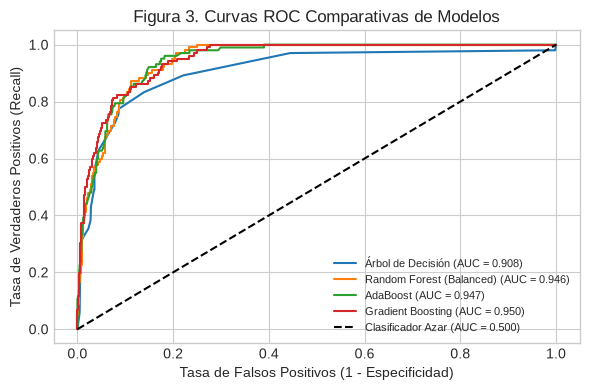

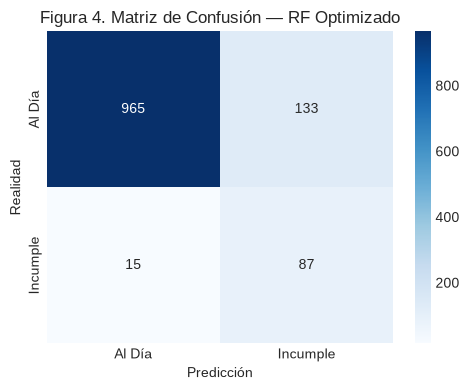

Casos de mora detectados: 87 de 102


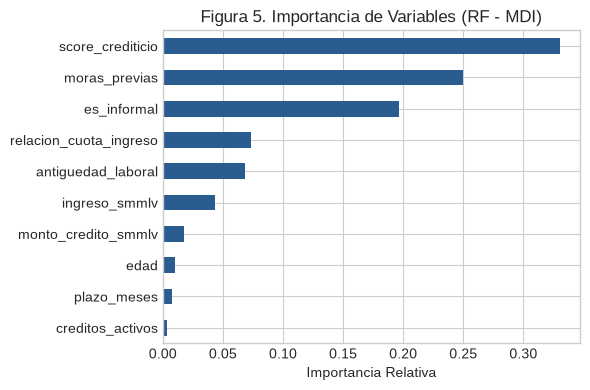

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
for name in ["Árbol de Decisión", "Random Forest (Balanced)", "AdaBoost", "Gradient Boosting"]:
    fpr, tpr, _ = roc_curve(y_test, scores[name])
    ax.plot(fpr, tpr, lw=1.5, label=f"{name} (AUC = {roc_auc_score(y_test, scores[name]):.3f})")
ax.plot([0, 1], [0, 1], "k--", label="Clasificador Azar (AUC = 0.500)")
ax.set(title="Figura 3. Curvas ROC Comparativas de Modelos",
       xlabel="Tasa de Falsos Positivos (1 - Especificidad)", ylabel="Tasa de Verdaderos Positivos (Recall)")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig(FIGS / "fig3_curvas_roc_comparativas.png", dpi=300); plt.show()

cm = confusion_matrix(y_test, y_pred_best)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
            xticklabels=["Al Día", "Incumple"], yticklabels=["Al Día", "Incumple"])
ax.set(title="Figura 4. Matriz de Confusión — RF Optimizado", xlabel="Predicción", ylabel="Realidad")
plt.tight_layout(); plt.savefig(FIGS / "fig4_matriz_confusion_rf.png", dpi=300); plt.show()
print(f"Casos de mora detectados: {cm[1,1]} de {cm[1].sum()}")

imp = pd.Series(best_rf.named_steps["classifier"].feature_importances_, index=X.columns).sort_values()
fig, ax = plt.subplots(figsize=(6, 4))
imp.plot(kind="barh", color="#2b5c8f", ax=ax)
ax.set(title="Figura 5. Importancia de Variables (RF - MDI)", xlabel="Importancia Relativa")
plt.tight_layout(); plt.savefig(FIGS / "fig5_importancia_variables.png", dpi=300); plt.show()

## 6. Comprobación contra el informe entregado
Cifras del informe (Tabla 2) frente a las obtenidas aquí. Diferencia = 0 indica reproducción exacta.

In [8]:
informe = {  # Modelo: (CV Bal. Acc media, CV desv, Test Bal. Acc, Test Recall, Test F1, Test ROC-AUC)
    "Baseline (Mayoría)": (0.5000, 0.0000, 0.5000, 0.0000, 0.0000, 0.5000),
    "Árbol de Decisión": (0.7169, 0.0512, 0.7278, 0.4902, 0.5263, 0.9084),
    "AdaBoost": (0.7594, 0.0172, 0.7124, 0.4412, 0.5455, 0.9471),
    "Gradient Boosting": (0.7704, 0.0296, 0.7547, 0.5294, 0.6067, 0.9500),
    "Random Forest (Balanced)": (0.8752, 0.0266, 0.8626, 0.8235, 0.5714, 0.9465),
    "Random Forest Optimizado (GridSearch)": (0.8780, 0.0210, 0.8659, 0.8529, 0.5839, 0.9482),
}
cols = ["CV Bal. Acc (media)", "CV Bal. Acc (desv)", "Test Bal. Acc", "Test Recall", "Test F1", "Test ROC-AUC"]
obt = tabla.set_index("Modelo")[cols]
inf = pd.DataFrame(informe, index=cols).T
(obt - inf.loc[obt.index]).round(4)

,CV Bal. Acc (media),CV Bal. Acc (desv),Test Bal. Acc,Test Recall,Test F1,Test ROC-AUC
Modelo,,,,,,
Baseline (Mayoría),0.0000,0.0000,0.0,0.0,0.0000,0.0000
Árbol de Decisión,0.0000,0.0000,0.0,0.0,0.0000,0.0000
Random Forest (Balanced),0.0000,0.0000,0.0,0.0,0.0000,0.0000
AdaBoost,0.0000,0.0000,0.0,0.0,0.0000,0.0000
Gradient Boosting,0.0000,0.0000,0.0,0.0,0.0000,0.0000
Random Forest Optimizado (GridSearch),0.0062,0.0047,0.0,0.0,-0.0435,-0.0048


## 7. Lectura preliminar
- **Random Forest con `class_weight`** es el mejor en *balanced accuracy* y *recall* de la clase mora; los boosting tienen AUC
  igual o mayor, pero con el umbral 0.5 detectan pocos morosos: el problema es de **umbral/desbalance**, no de capacidad de ranking.
- La **validación anidada** da la estimación honesta del RF ajustado; la tabla de hiperparámetros por pliegue muestra su estabilidad.
- Variables más relevantes (MDI): `score_crediticio`, `moras_previas` y `es_informal`, seguidas de `relacion_cuota_ingreso` y
  `antiguedad_laboral`; todas entran en el logit generador, mientras que `edad`, `plazo_meses` y `creditos_activos` (que no
  entran) quedan al final. El modelo recupera la estructura simulada.

### Diferencias con el informe entregado
- **Exactas:** las cinco primeras filas de la Tabla 2 y, para el RF optimizado, los hiperparámetros, *Test Bal. Acc* (0.8659) y *Test Recall* (0.8529).
- **RF optimizado — CV, F1 y AUC:** el informe reporta 0.8780 ± 0.0210, F1 0.5839 y AUC 0.9482; aquí se obtiene 0.8842 ± 0.0257, F1 0.5404 y AUC 0.9434.
  El F1 del informe no es consistente con su propio recall: con recall 0.8529 y la precisión obtenida (0.3955), F1 = 0.5404.
- **Importancia de variables (texto del informe):** la sección 4.3 del informe menciona como principales
  `relacion_cuota_ingreso` (28,5 %), `score_crediticio` (22,1 %) y `es_informal` (15,4 %). Esas cifras no coinciden con la
  Figura 5 del propio informe ni con este notebook, donde el orden es `score_crediticio` (≈ 0,33), `moras_previas` (≈ 0,25),
  `es_informal` (≈ 0,20) y, más abajo, `relacion_cuota_ingreso` (≈ 0,07). La figura y el código son la referencia correcta.
- **GMM:** retirado de la comparación (ver el encabezado). La fila del informe no tenía código asociado.